# Transfer by receiver family — original, data/weight-seed, and full-seed receivers on one axis

This notebook expands the §4e grouped box plot of `transfer_factor_decomposition.ipynb` (six
PolyPythias receivers) with the original-init receiver and the fully re-randomized full-seed
receivers of `fsfact_transfer_analysis.ipynb` / `seed2seed_ds1_ws1.ipynb` §11, so all **ten**
Pythia-160m receiver bases appear on a single axis under one selection and one dead label.

**Receiver families** (defined relative to the original-init senders used here):

| family | receivers | relation to the sender's base |
| --- | --- | --- |
| `same-model` | `orig` (`pythia-160m`) | teacher base = receiver base |
| `shared-init` | `ds1-3`, `ws1-3` | `ds*` share the initialization; `ws*` share the initialization **and** the data order (they are SGD-noise re-runs of the original run, not independent inits) |
| `full-seed` | `fs1-3` (`pythia-160m-seed{1,2,3}`) | share neither factor |

**Population.** Senders are the ORIGINAL-init teachers only (`teacher-pythia-160m`), teacher
seed 1, the shared top-10 teacher tags, number pool `ex10-20_prefix_n100k`, students at 20
epochs on the core56 cells (`K/K*` 0.46–1.25) and **student seed 1 only**.  The seed-1
restriction is what makes the ds/ws arms like-for-like with the fs arms, which were run at
seed 1 only.

**Reading contract for the label.**  The operative collapse label is the per-receiver
unigram-anchored cut `Delta_cross = H_uni - ce_base` (`analysis.labels.anchored_cuts`, pool
pp1): a run is dead iff its probe KL exceeds the cut **of its own receiver base**.  A run with
no probe record is unlabelled — NaN, never "alive" and never re-cut against a flat fallback.
Row 2 of the figure therefore drops both dead and unprobed runs, and reports how many of each.
The flat `probe_io.DEAD_KL_CUT` appears once, explicitly labelled comparison-only.

## 1. Setup — receivers, families, design, anchored cuts

Row unit of the tables below: one receiver base (ten rows).  No run data is read yet; this
cell fixes the design (56 student cells × 10 teachers) and prints each receiver's anchored cut.

In [1]:
from __future__ import annotations

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import fsfact_transfer as fsx
from subliminal_learning.analysis import labels
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import transfer_factors as tf
from subliminal_learning.analysis.probe_cache import load_probe_cache
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT  # COMPARISON ONLY
from subliminal_learning.teachers.run_layout import model_dir_parts_from_name

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

ANIMALS = list(tf.FOCUS_ANIMALS)                 # dog, cat, lion, pig
RECEIVERS = list(fsx.RECEIVERS)                  # orig, ds1-3, ws1-3, fs1-3 (display order)
FULL_BASES = [fsx.RECEIVER_BASE[r] for r in RECEIVERS]
DATASET = "ex10-20_prefix_n100k"
NUMBERS_BASE = "pythia-160m"                     # the ORIGINAL-init sender
STUDENT_SEED = 1
P_VMAX = 0.2                                     # house colour scale for mean test p

core65, TOP10 = tf.load_core65_design(ROOT)
core56 = core65[core65.subset != "lowk9"].reset_index(drop=True)
CELL_TAGS = list(core56.student_tag)
KREL = core56.set_index("student_tag")["K_rel"].to_dict()
N_CELLS56, N_TEACH = len(CELL_TAGS), len(TOP10)

# OPERATIVE dead label: one anchored cut per RECEIVER base. All ten are in the pp1 anchor
# record, so no receiver falls back to a flat cut.
ANCHOR_CUTS = labels.anchored_cuts(OUTPUT_ROOT, FULL_BASES)          # keyed by full base name
CUT_BY_RECEIVER = {r: ANCHOR_CUTS[fsx.RECEIVER_BASE[r]] for r in RECEIVERS}

design = pd.DataFrame({
    "receiver": RECEIVERS,
    "base": FULL_BASES,
    "family": [fsx.RECEIVER_FAMILY[r] for r in RECEIVERS],
    "prior_label": [fsx.RECEIVER_PRIOR_LABEL[r] for r in RECEIVERS],
    "anchored_cut": [CUT_BY_RECEIVER[r] for r in RECEIVERS],
}).set_index("receiver")
print(f"design: {N_CELLS56} core56 cells (K/K* {core56.K_rel.min():.2f}-{core56.K_rel.max():.2f}) "
      f"x {N_TEACH} shared top-10 teachers x {len(ANIMALS)} animals x {len(RECEIVERS)} receivers, "
      f"student seed {STUDENT_SEED} only, pool {DATASET}")
print(f"comparison-only flat cut: {DEAD_KL_CUT} nats")
print("receiver bases and their OPERATIVE anchored dead cuts (nats):")
display(design.round(3))

priors = tf.load_priors(OUTPUT_ROOT)
TEST_PRIOR = {(row.animal, row.base_label): row.test_prior
              for row in priors.dropna(subset=["test_prior"]).itertuples()}


def prior_of(animal: str, receiver: str) -> float:
    """The receiver base's own held-out test prior for `animal` (NaN when unmeasured)."""
    return float(TEST_PRIOR.get((animal, fsx.RECEIVER_PRIOR_LABEL[receiver]), np.nan))


prior_tab = pd.DataFrame({a: {r: prior_of(a, r) for r in RECEIVERS} for a in ANIMALS})
print("measured base test priors p(animal) on the held-out test prompts (row = receiver):")
display(prior_tab.round(4))

design: 56 core56 cells (K/K* 0.46-1.25) x 10 shared top-10 teachers x 4 animals x 10 receivers, student seed 1 only, pool ex10-20_prefix_n100k
comparison-only flat cut: 4.0 nats
receiver bases and their OPERATIVE anchored dead cuts (nats):


,base,family,prior_label,anchored_cut
receiver,,,,
orig,pythia-160m,same-model,original,5.096
ds1,pythia-160m-data-seed1,shared-init,data-seed1,5.123
ds2,pythia-160m-data-seed2,shared-init,data-seed2,5.120
ds3,pythia-160m-data-seed3,shared-init,data-seed3,5.094
ws1,pythia-160m-weight-seed1,shared-init,weight-seed1,5.055
ws2,pythia-160m-weight-seed2,shared-init,weight-seed2,5.169
ws3,pythia-160m-weight-seed3,shared-init,weight-seed3,5.130
fs1,pythia-160m-seed1,full-seed,full-seed1,5.137
fs2,pythia-160m-seed2,full-seed,full-seed2,5.167


measured base test priors p(animal) on the held-out test prompts (row = receiver):


,dog,cat,lion,pig
orig,0.0096,0.0033,0.0047,0.0025
ds1,0.0133,0.0048,0.0050,0.0026
ds2,0.0110,0.0058,0.0030,0.0018
ds3,0.0090,0.0048,0.0023,0.0013
ws1,0.0077,0.0056,0.0038,0.0016
ws2,0.0152,0.0074,0.0043,0.0033
ws3,0.0067,0.0036,0.0035,0.0021
fs1,0.0082,0.0037,0.0014,0.0017
fs2,0.0084,0.0076,0.0031,0.0015
fs3,0.0106,0.0040,0.0023,0.0020


## 2. Load the seed-1 population and its integrity readout

Row unit: **one landed seed-run** (animal × receiver × teacher × student cell, seed 1).
Selection: original-init senders, top-10 teachers, core56 cells, epoch 20.  `cl.load_law_runs`
silently skips lineage directories that do not exist, which is the intended degradation — an
arm that was never run simply contributes zero rows and shows up as `n=0` downstream.

Pile KL comes from one cached probe sweep per animal (`pool_version="pp1"`); `+inf` marks a
non-finite adapter (dead by any cut) and a missing record leaves NaN (**not probed**, hence
unlabelled).  The coverage table below is per (animal × receiver): landed runs, complete cells
(all ten teachers present on a cell, out of 56), probed runs, and the dead fraction under the
operative anchored cut next to the comparison-only flat cut.

In [2]:
def load_receiver_runs(sender_base: str, animal: str) -> pd.DataFrame:
    """All of one sender's seed-1 core56 runs into every one of the ten receivers.

    One batched `load_law_runs` call over the 10x10 lineage list plus ONE probe-cache sweep,
    rather than a call per receiver (the cache cost is per CALL, not per row)."""
    lineages = [(t, t, b) for b in FULL_BASES for t in TOP10]
    _, r = cl.load_law_runs(OUTPUT_ROOT, animal=animal, numbers_base=sender_base,
                            dataset=DATASET, lineages=lineages)
    cols = ["animal", "receiver", "family", "teacher", "student_tag", "K_rel", "seed",
            "test", "pile_kl", "dead", "dead_cmp"]
    if len(r) == 0:
        return pd.DataFrame(columns=cols)
    r = r[r.seed.eq(STUDENT_SEED) & r.student_tag.isin(CELL_TAGS)].copy()
    if len(r) == 0:
        return pd.DataFrame(columns=cols)
    r = r.rename(columns={"teacher_tag": "teacher"})
    r["animal"] = animal
    r["receiver"] = r.base.map(fsx.BASE_RECEIVER)     # map on the FULL base, not base_label
    r["family"] = r.receiver.map(fsx.RECEIVER_FAMILY)
    r["K_rel"] = r.student_tag.map(KREL).astype(float)
    rel = [str(Path("students") / animal / Path(*model_dir_parts_from_name(base))
               / f"teacher-{sender_base}" / f"{t}_tseed1" / DATASET / c / f"ftseed{int(s)}")
           for base, t, c, s in zip(r.base, r.teacher, r.student_tag, r.seed)]
    cached = load_probe_cache(OUTPUT_ROOT, rel, pool_version="pp1")
    klmap = dict(zip(cached["run_path"], cached["kl"])) if len(cached) else {}
    r["pile_kl"] = [float(klmap.get(p, np.nan)) for p in rel]
    r["dead"] = labels.label_dead_kl(r, CUT_BY_RECEIVER, kl_col="pile_kl",
                                     base_col="receiver").astype(float)
    r["dead_cmp"] = labels.label_dead_kl(r, DEAD_KL_CUT, kl_col="pile_kl").astype(float)
    return r[cols]


runs = pd.concat([load_receiver_runs(NUMBERS_BASE, a) for a in ANIMALS], ignore_index=True)
runs["probed"] = runs.pile_kl.notna()
runs["alive"] = np.isfinite(runs.pile_kl) & (runs.dead == 0)

full_index = pd.MultiIndex.from_product([ANIMALS, RECEIVERS], names=["animal", "receiver"])
cov = (runs.groupby(["animal", "receiver"])
       .apply(lambda g: pd.Series({
           "landed": len(g),
           "complete_cells": fsx.count_complete_cells(g, N_TEACH),
           "probed": int(g.probed.sum()),
           "probe_cells": int(g.loc[g.probed, "student_tag"].nunique()),
           "alive": int(g.alive.sum()),
           "dead_frac_anchored": float(g.dead.mean()) if g.dead.notna().any() else np.nan,
           "dead_frac_flat_cmp": float(g.dead_cmp.mean()) if g.dead_cmp.notna().any() else np.nan,
       }), include_groups=False)
       .reindex(full_index)
       .fillna({"landed": 0, "complete_cells": 0, "probed": 0, "probe_cells": 0,
                "alive": 0}))
for c in ("landed", "complete_cells", "probed", "probe_cells", "alive"):
    cov[c] = cov[c].astype(int)
# Arms whose probed subset is SMALLER than what landed: their alive-only view is not the
# landed population minus the dead runs, it is a different (and here often sub-block) sample
# of cells, so a 0% dead fraction there can be a coverage artifact.
PARTIAL = cov[(cov.landed > 0) & (cov.probed < cov.landed)].copy()

print(f"landed {len(runs):,} seed-1 runs; probed {int(runs.probed.sum()):,}; "
      f"alive (anchored) {int(runs.alive.sum()):,}")
print(f"coverage per (animal x receiver): complete_cells (landed set) and probe_cells "
      f"(PROBED subset) are both out of {N_CELLS56}; `dead_frac_flat_cmp` uses the flat "
      f"{DEAD_KL_CUT}-nat cut and is COMPARISON ONLY:")
display(cov.round(3))
print(f"\nPARTIALLY PROBED arms ({len(PARTIAL)}): the alive-only row of the figure is a "
      "DIFFERENT subsample of cells for these, not the landed set minus its dead runs -- "
      "their dead fractions mix collapse with probe coverage:")
for (a, rcv), row in PARTIAL.iterrows():
    print(f"  {a:5s} {rcv:4s}: probed {int(row.probed)}/{int(row.landed)} runs spanning "
          f"{int(row.probe_cells)}/{N_CELLS56} cells (landed set covers "
          f"{int(runs[(runs.animal == a) & (runs.receiver == rcv)].student_tag.nunique())} "
          f"cells); dead {row.dead_frac_anchored:.0%}")

pile_probe cache: 5109 rows of 66522 cached (0 added, 0 refreshed, 491 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2632 rows of 66522 cached (0 added, 0 refreshed, 726 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 4878 rows of 66522 cached (0 added, 0 refreshed, 722 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2640 rows of 66522 cached (0 added, 0 refreshed, 720 inventory paths without a record, 0 unreadable/kept)
landed 17,918 seed-1 runs; probed 15,259; alive (anchored) 13,231
coverage per (animal x receiver): complete_cells (landed set) and probe_cells (PROBED subset) are both out of 56; `dead_frac_flat_cmp` uses the flat 4.0-nat cut and is COMPARISON ONLY:


landed  complete_cells  probed  probe_cells  alive  dead_frac_anchored  dead_frac_flat_cmp
animal receiver                                                                                            
dog    orig         560              56     560           56    439               0.216               0.302
       ds1          560              56     560           56    469               0.162               0.218
       ds2          560              56     560           56    491               0.123               0.195
       ds3          560              56     380           56    338               0.111               0.179
       ws1          560              56     560           56    411               0.266               0.332
       ws2          560              56     560           56    520               0.071               0.148
       ws3          560              56     249           56    243               0.024               0.036
       fs1          560              56     560           56    416               0.257               0.327
       fs2          560              56     560           56    548               0.021               0.052
       fs3          560              56     560           56    427               0.238               0.291
cat    orig           0               0       0            0      0                 NaN                 NaN
       ds1          560              56     560           56    481               0.141               0.211
       ds2          560              56     560           56    502               0.104               0.179
       ds3          560              56     200           20    200               0.000               0.000
       ws1          560              56     556           56    423               0.239               0.302
       ws2          560              56     560           56    528               0.057               0.129
       ws3          558              54     196           20    196               0.000               0.000
       fs1            0               0       0            0      0                 NaN                 NaN
       fs2            0               0       0            0      0                 NaN                 NaN
       fs3            0               0       0            0      0                 NaN                 NaN
lion   orig         560              56     560           56    454               0.189               0.271
       ds1          560              56     559           56    472               0.156               0.213
       ds2          560              56     560           56    493               0.120               0.182
       ds3          560              56     200           20    200               0.000               0.000
       ws1          560              56     559           56    419               0.250               0.299
       ws2          560              56     560           56    524               0.064               0.127
       ws3          560              56     200           20    200               0.000               0.000
       fs1          560              56     560           56    439               0.216               0.300
       fs2          560              56     560           56    554               0.011               0.054
       fs3          560              56     560           56    449               0.198               0.262
pig    orig           0               0       0            0      0                 NaN                 NaN
       ds1          560              56     560           56    502               0.104               0.164
       ds2          560              56     560           56    516               0.079               0.143
       ds3          560              56     200           20    199               0.005               0.005
       ws1          560              56     560           56    443               0.209               0.262
       ws2          5


PARTIALLY PROBED arms (11): the alive-only row of the figure is a DIFFERENT subsample of cells for these, not the landed set minus its dead runs -- their dead fractions mix collapse with probe coverage:
  dog   ds3 : probed 380/560 runs spanning 56/56 cells (landed set covers 56 cells); dead 11%
  dog   ws3 : probed 249/560 runs spanning 56/56 cells (landed set covers 56 cells); dead 2%
  cat   ds3 : probed 200/560 runs spanning 20/56 cells (landed set covers 56 cells); dead 0%
  cat   ws1 : probed 556/560 runs spanning 56/56 cells (landed set covers 56 cells); dead 24%
  cat   ws3 : probed 196/558 runs spanning 20/56 cells (landed set covers 56 cells); dead 0%
  lion  ds1 : probed 559/560 runs spanning 56/56 cells (landed set covers 56 cells); dead 16%
  lion  ds3 : probed 200/560 runs spanning 20/56 cells (landed set covers 56 cells); dead 0%
  lion  ws1 : probed 559/560 runs spanning 56/56 cells (landed set covers 56 cells); dead 25%
  lion  ws3 : probed 200/560 runs spanning 20/56

## 3. The figure — transfer distribution per (receiver × animal), all runs vs alive only

Row unit of each box: **one landed seed-1 run's** held-out `test` p(target animal), pooled over
the 56 core56 cells and the 10 teachers of that arm (no cell-level averaging — the pool is
runs).  Boxes are the IQR with a black median and 5–95% whiskers, fliers hidden; the y axis is
log with values clipped to 1e-6 for display only.  The dotted tick inside each box is that
receiver base's own measured test prior for that animal.

The two charts do **not** share an x axis — each carries its own ticks and axis title, so
either can be read (or cropped out) on its own.

- **Row 1**: every landed run of the arm.  Annotation `n` = runs, `c` = complete cells / 56.
- **Row 2**: alive runs only — finite probe KL at or below the receiver's anchored cut, so both
  dead and unprobed runs are dropped.  Annotation `n` = alive/probed and the dead fraction.

Arms with nothing landed print a red `n=0`; arms that landed but were never probed print a red
`no probes` in row 2 and draw no box.

**Partial probe coverage.**  Row 2's annotation is red wherever `probed < landed`.  For those
arms row 2 is not row 1 with its dead runs removed — it is a *different, smaller* subsample of
student cells (see `probe_cells` in §2), so any row-1 → row-2 shift there mixes the dead label
with the coverage change and their low dead fractions may be a coverage artifact.

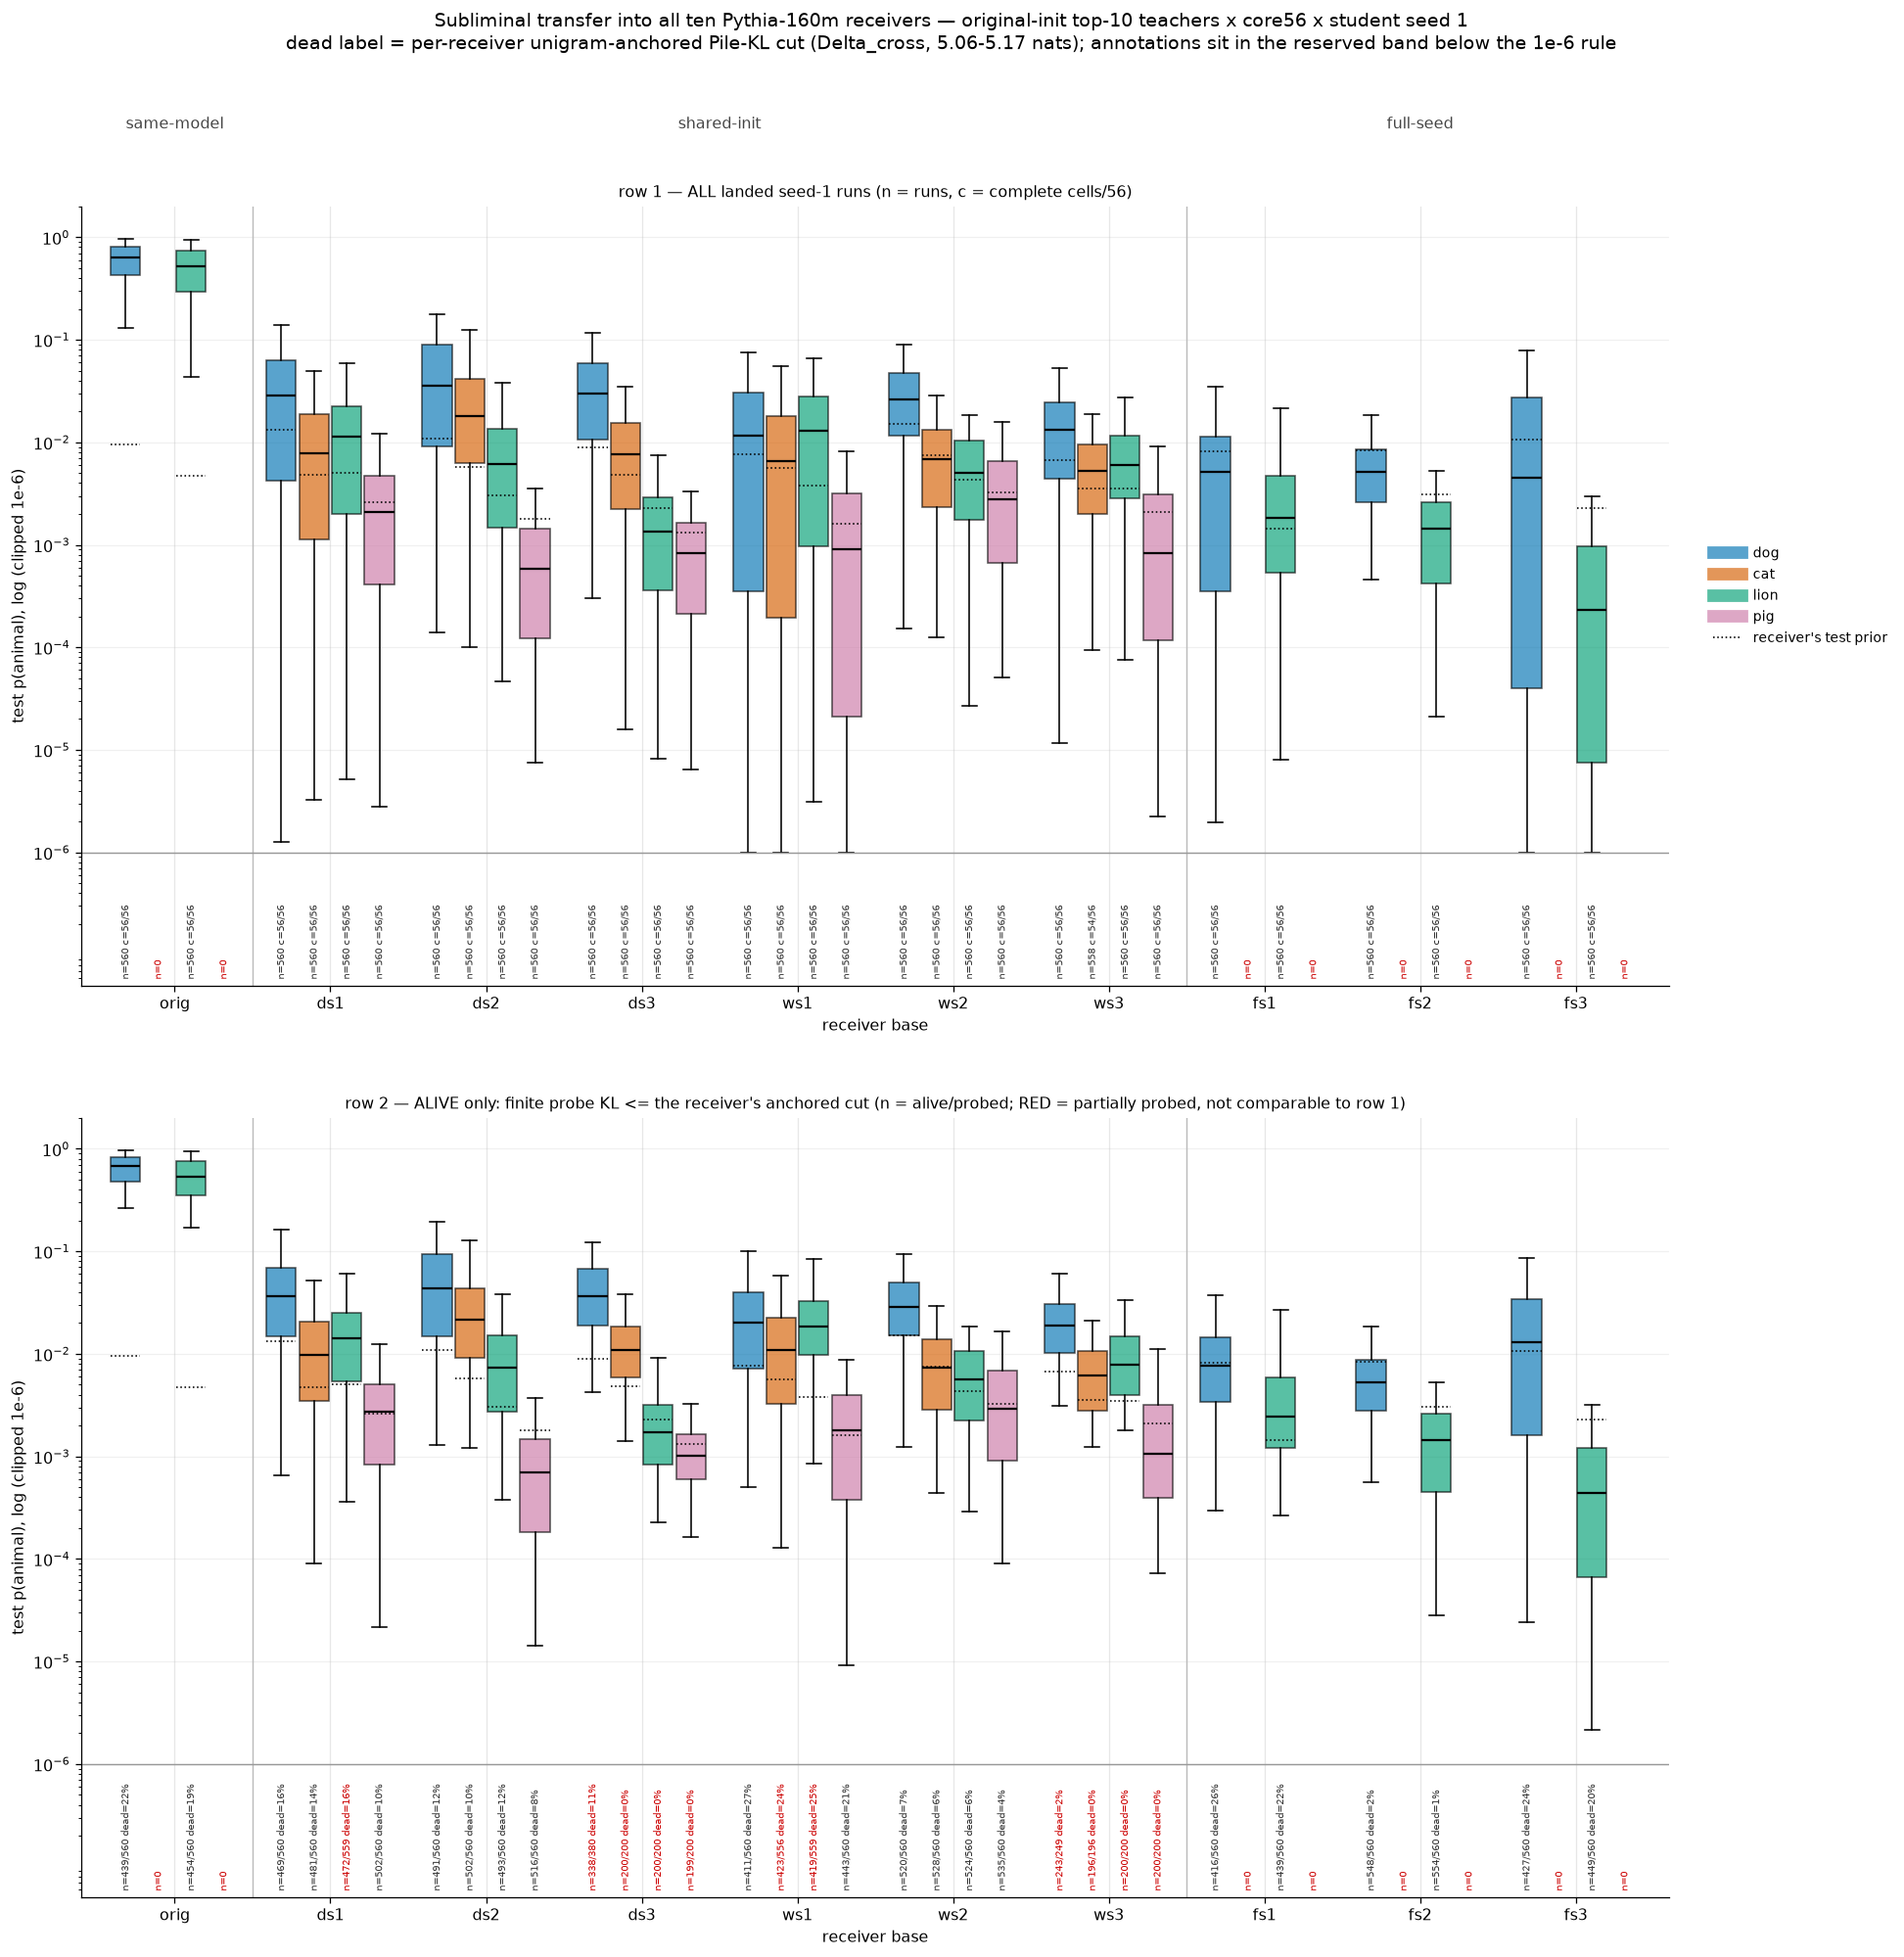

wrote docs/results/figures/transfer_receiver_family_boxplots.png


In [3]:
W, GAP = 0.19, 0.21                       # box width / within-receiver animal spacing
FAM_BOUNDS = [0.5, 6.5]                   # same-model | shared-init | full-seed
FAM_SPANS = {"same-model": (0, 0), "shared-init": (1, 6), "full-seed": (7, 9)}

CLIP, BAND_BOT = 1e-6, 10 ** -7.3   # data floor / bottom of the reserved annotation band
NOTE_Y = 10 ** -7.24                # every annotation is drawn INSIDE the band, never on data

# taller than wide-default: the 1.3-decade annotation band must fit the rotated
# labels in inches, so the axes height is what keeps the text clear of the 1e-6 rule.
fig, axes = plt.subplots(2, 1, figsize=(17, 17))   # NOT sharex: each chart keeps its own axis
for ax, mode in zip(axes, ["all", "alive"], strict=True):
    for j, a in enumerate(ANIMALS):
        offs = (j - (len(ANIMALS) - 1) / 2) * GAP
        for i, rcv in enumerate(RECEIVERS):
            g = runs[(runs.animal == a) & (runs.receiver == rcv)]
            x = i + offs
            note_color = "#333333"
            if len(g) == 0:
                ax.annotate("n=0", (x, NOTE_Y), ha="center", va="bottom", fontsize=6.5,
                            rotation=90, color="#c00")
                continue
            if mode == "all":
                vals = g["test"]
                note = f"n={len(g)} c={fsx.count_complete_cells(g, N_TEACH)}/{N_CELLS56}"
            else:
                n_probed = int(g.probed.sum())
                if n_probed == 0:
                    ax.annotate("no probes", (x, NOTE_Y), ha="center", va="bottom",
                                fontsize=6.5, rotation=90, color="#c00")
                    continue
                vals = g.loc[g.alive, "test"]
                note = f"n={len(vals)}/{n_probed} dead={g.dead.mean():.0%}"
                if n_probed < len(g):     # partially probed: NOT comparable to its row-1 twin
                    note_color = "#c00"
            if len(vals):
                bp = ax.boxplot([vals.clip(lower=CLIP)], positions=[x], widths=W,
                                whis=(5, 95), showfliers=False, patch_artist=True,
                                medianprops=dict(color="black", lw=1.4))
                bp["boxes"][0].set(facecolor=aplots.ANIMAL_COLORS[a], alpha=0.65)
                p = prior_of(a, rcv)
                if np.isfinite(p):
                    ax.plot([x - W / 2, x + W / 2], [p, p], color="k", lw=1.0, ls=":")
            ax.annotate(note, (x, NOTE_Y), ha="center", va="bottom", fontsize=6.5,
                        rotation=90, color=note_color)
    for b in FAM_BOUNDS:
        ax.axvline(b, color="#bbbbbb", lw=0.9)
    ax.set_yscale("log")
    # The band below CLIP holds the annotations ONLY -- no datum can enter it (values are
    # clipped at CLIP), and the rule at CLIP marks where the data region ends.
    ax.set_ylim(BAND_BOT, 2.0)
    ax.axhline(CLIP, color="#999999", lw=0.9)
    ax.set_yticks([10.0 ** e for e in range(-6, 1)])
    ax.set_ylabel("test p(animal), log (clipped 1e-6)")
    ax.grid(axis="y", which="major", alpha=0.18)
    # Both charts carry their own ticks and axis title, so either one is readable cropped out.
    ax.set_xlim(-0.6, len(RECEIVERS) - 0.4)
    ax.set_xticks(range(len(RECEIVERS)))
    ax.set_xticklabels(RECEIVERS)
    ax.tick_params(axis="x", labelbottom=True, bottom=True)
    ax.set_xlabel("receiver base")

axes[0].set_title("row 1 — ALL landed seed-1 runs (n = runs, c = complete cells/56)",
                  fontsize=10, pad=6)
axes[1].set_title("row 2 — ALIVE only: finite probe KL <= the receiver's anchored cut "
                  "(n = alive/probed; RED = partially probed, not comparable to row 1)",
                  fontsize=10)
for fam, (lo, hi) in FAM_SPANS.items():
    axes[0].annotate(fam, ((lo + hi) / 2, 1.10), xycoords=("data", "axes fraction"),
                     ha="center", fontsize=10, color="#444444", annotation_clip=False)
for a in ANIMALS:
    axes[0].plot([], [], color=aplots.ANIMAL_COLORS[a], lw=8, alpha=0.65, label=a)
axes[0].plot([], [], color="k", lw=1, ls=":", label="receiver's test prior")
aplots.right_legend(axes[0], fontsize=9)
fig.suptitle(
    "Subliminal transfer into all ten Pythia-160m receivers — original-init top-10 teachers x "
    "core56 x student seed 1\n"
    "dead label = per-receiver unigram-anchored Pile-KL cut (Delta_cross, 5.06-5.17 nats); "
    "annotations sit in the reserved band below the 1e-6 rule",
    fontsize=12, y=1.02)
fig.tight_layout(h_pad=4.0)   # room for the upper chart's tick labels + the lower one's title
figure_path = ROOT / "docs/results/figures/transfer_receiver_family_boxplots.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"wrote {figure_path.relative_to(ROOT)}")

## 3b. Every transfer direction — all senders × all receivers, diagonal included

§3 fixes the sender at the original init.  This section generalizes it to the full directed
matrix: for each animal, every one of the ten bases is tried as the **sender** (the
`teacher-<base>` level of the tree) into every one of the ten **receivers**, the same-base
diagonal included.  §5 shows the means of exactly this population as heatmaps; §3b is its
distribution view.

Row unit, selection and label are identical to §3: one landed seed-1 run, the shared top-10
teacher tags (one manifest, used unchanged on every animal arm), core56 cells, epoch 20, and
the per-receiver anchored Pile-KL cut for the dead label.  The population frame `all_runs` is
built in the cell below and is the SAME frame §5 consumes, so the sweep is paid once; the
original-init sender rows are reused from §2's `runs` rather than reloaded.

**Missing directions are unrun arms, not floors.**  Only off-diagonal directions that exist on
disk are plotted — no slot is reserved for an off-diagonal that was never run.  The **diagonal
slot is always reserved** in every sender group and carries a red `not run` marker when that
same-base direction has no runs, so a missing diagonal can never read as an oversight or a
floor.  The `ds*` and `ws*` same-base arms were never run at the core56 cells (their same-model
students exist only at the standard recipe ladder), whereas the `orig` and `fs*` diagonals were
run here.  The partial-probe
caution of §2/§3 carries over unchanged: wherever `probed < landed` the alive-only chart is a
different (smaller) subsample of cells, and its annotation is drawn in red.

In [4]:
# The full directed population, loaded ONCE here and reused by §5. The orig-sender rows are
# §2's `runs` (already loaded); only the nine other senders are read from disk.
_frames = [runs.assign(sender="orig")]
for a in ANIMALS:
    for snd in RECEIVERS:
        if snd == "orig":
            continue
        f = load_receiver_runs(fsx.RECEIVER_BASE[snd], a)
        if len(f):
            _frames.append(f.assign(sender=snd))
all_runs = pd.concat(_frames, ignore_index=True)
all_runs["probed"] = all_runs.pile_kl.notna()
all_runs["alive"] = np.isfinite(all_runs.pile_kl) & (all_runs.dead == 0)
all_runs["diagonal"] = all_runs.sender.eq(all_runs.receiver)
# Sender-relative relation of each run's direction (NOT the receiver-relative family of §3/§4).
all_runs["relation"] = [fsx.direction_relation(x, y)
                        for x, y in zip(all_runs.sender, all_runs.receiver)]

_R_ORD = {r: i for i, r in enumerate(RECEIVERS)}
DIRECTIONS = {a: [(snd, rcv) for snd in RECEIVERS for rcv in RECEIVERS
                  if ((all_runs.animal == a) & (all_runs.sender == snd)
                      & (all_runs.receiver == rcv)).any()]
              for a in ANIMALS}
print(f"directed population: {len(all_runs):,} landed seed-1 runs, "
      f"{int(all_runs.probed.sum()):,} probed, {int(all_runs.alive.sum()):,} alive (anchored)")
for a in ANIMALS:
    d = DIRECTIONS[a]
    diag = [f"{x}->{y}" for x, y in d if x == y]
    print(f"  {a:5s}: {len(d):3d} landed directions from {len({x for x, _ in d})} sender(s)"
          f"; diagonals present: {diag or 'none'}")
# Plot slots: every LANDED direction, plus a reserved slot for each sender's own diagonal
# even when it never ran (drawn as a red `not run` marker instead of a box).
SLOTS = {a: sorted({*DIRECTIONS[a], *((snd, snd) for snd, _ in DIRECTIONS[a])},
                   key=lambda d: (_R_ORD[d[0]], _R_ORD[d[1]]))
         for a in ANIMALS}
for a in ANIMALS:
    missing = [f"{x}->{y}" for x, y in SLOTS[a] if (x, y) not in DIRECTIONS[a]]
    print(f"  {a:5s}: reserved-but-unrun diagonals: {missing or 'none'}")
print(f"absent off-diagonal directions were never run at these cells (of "
      f"{len(RECEIVERS) ** 2} possible per animal); the ds*/ws* same-base arms in particular "
      "were never run on core56 -- their same-model students exist only at the std ladder")

pile_probe cache: 1680 rows of 66522 cached (0 added, 0 refreshed, 1680 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1680 rows of 66522 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1680 rows of 66522 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2800 rows of 66522 cached (0 added, 0 refreshed, 378 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1680 rows of 66522 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1680 rows of 66522 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


... (2 outputs left out)

pile_probe cache: 2240 rows of 66522 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2169 rows of 66522 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 560 rows of 66522 cached (0 added, 0 refreshed, 405 inventory paths without a record, 0 unreadable/kept)


directed population: 41,030 landed seed-1 runs, 35,908 probed, 31,507 alive (anchored)
  dog  :  46 landed directions from 10 sender(s); diagonals present: ['orig->orig', 'fs1->fs1', 'fs2->fs2', 'fs3->fs3']
  cat  :   6 landed directions from 1 sender(s); diagonals present: none
  lion :  16 landed directions from 3 sender(s); diagonals present: ['orig->orig', 'fs1->fs1']
  pig  :   6 landed directions from 1 sender(s); diagonals present: none
  dog  : reserved-but-unrun diagonals: ['ds1->ds1', 'ds2->ds2', 'ds3->ds3', 'ws1->ws1', 'ws2->ws2', 'ws3->ws3']
  cat  : reserved-but-unrun diagonals: ['orig->orig']
  lion : reserved-but-unrun diagonals: ['fs2->fs2']
  pig  : reserved-but-unrun diagonals: ['orig->orig']
absent off-diagonal directions were never run at these cells (of 100 possible per animal); the ds*/ws* same-base arms in particular were never run on core56 -- their same-model students exist only at the std ladder


### 3b figure — one all-runs chart and one alive-only chart per animal

Row unit of a box: one landed seed-1 run's held-out `test` p(target animal), pooled over the
arm's core56 cells and top-10 teachers.  Boxes are grouped **by sender** (light separators,
sender named under the axis) and ordered by receiver inside a group; only landed directions get
a slot.  Colour is the **relationship between the sender and the receiver**
(`fsfact_transfer.direction_relation`) — a property of the pair, never the identity of the
receiver:

- `same model` — sender = receiver.  This is the diagonal and it applies to *every* sender, so
  `fs1 → fs1` is coloured exactly like `orig → orig`.
- `shared init, different data order` — the two differ but both lie in the
  `{orig, ds1-3, ws1-3}` block, which all share one initialization.
- `different init` — the two differ and one end is a fully re-randomized base.

*Accuracy caveat on the middle class*: the `ws*` bases are SGD-noise re-runs that share the
original run's data order as well as its initialization, so directions such as `orig → ws1` or
`ws1 → ws2` vary neither the init nor the data order — only the training noise — yet still sit
in this class under the three-way naming.

This colouring is sender-relative and therefore differs from §3/§4, where the sender is fixed at
the original init and the receiver-relative family naming is the correct one: here `ds1 → orig`
is a cross-model direction (`shared init, different data order`), not a same-model one.  A **thick black edge marks
the same-model diagonal**, which is same-model distillation and a different regime from
cross-base transfer.  All §3 conventions are kept: log y clipped at 1e-6, IQR box, black median, 5–95%
whiskers, no fliers, annotations in the reserved band below the rule, red annotation wherever
`probed < landed`, red `n=0` for an empty direction.  Every chart carries its own x axis and
title, and all animals share one x scale so box widths are comparable across them.

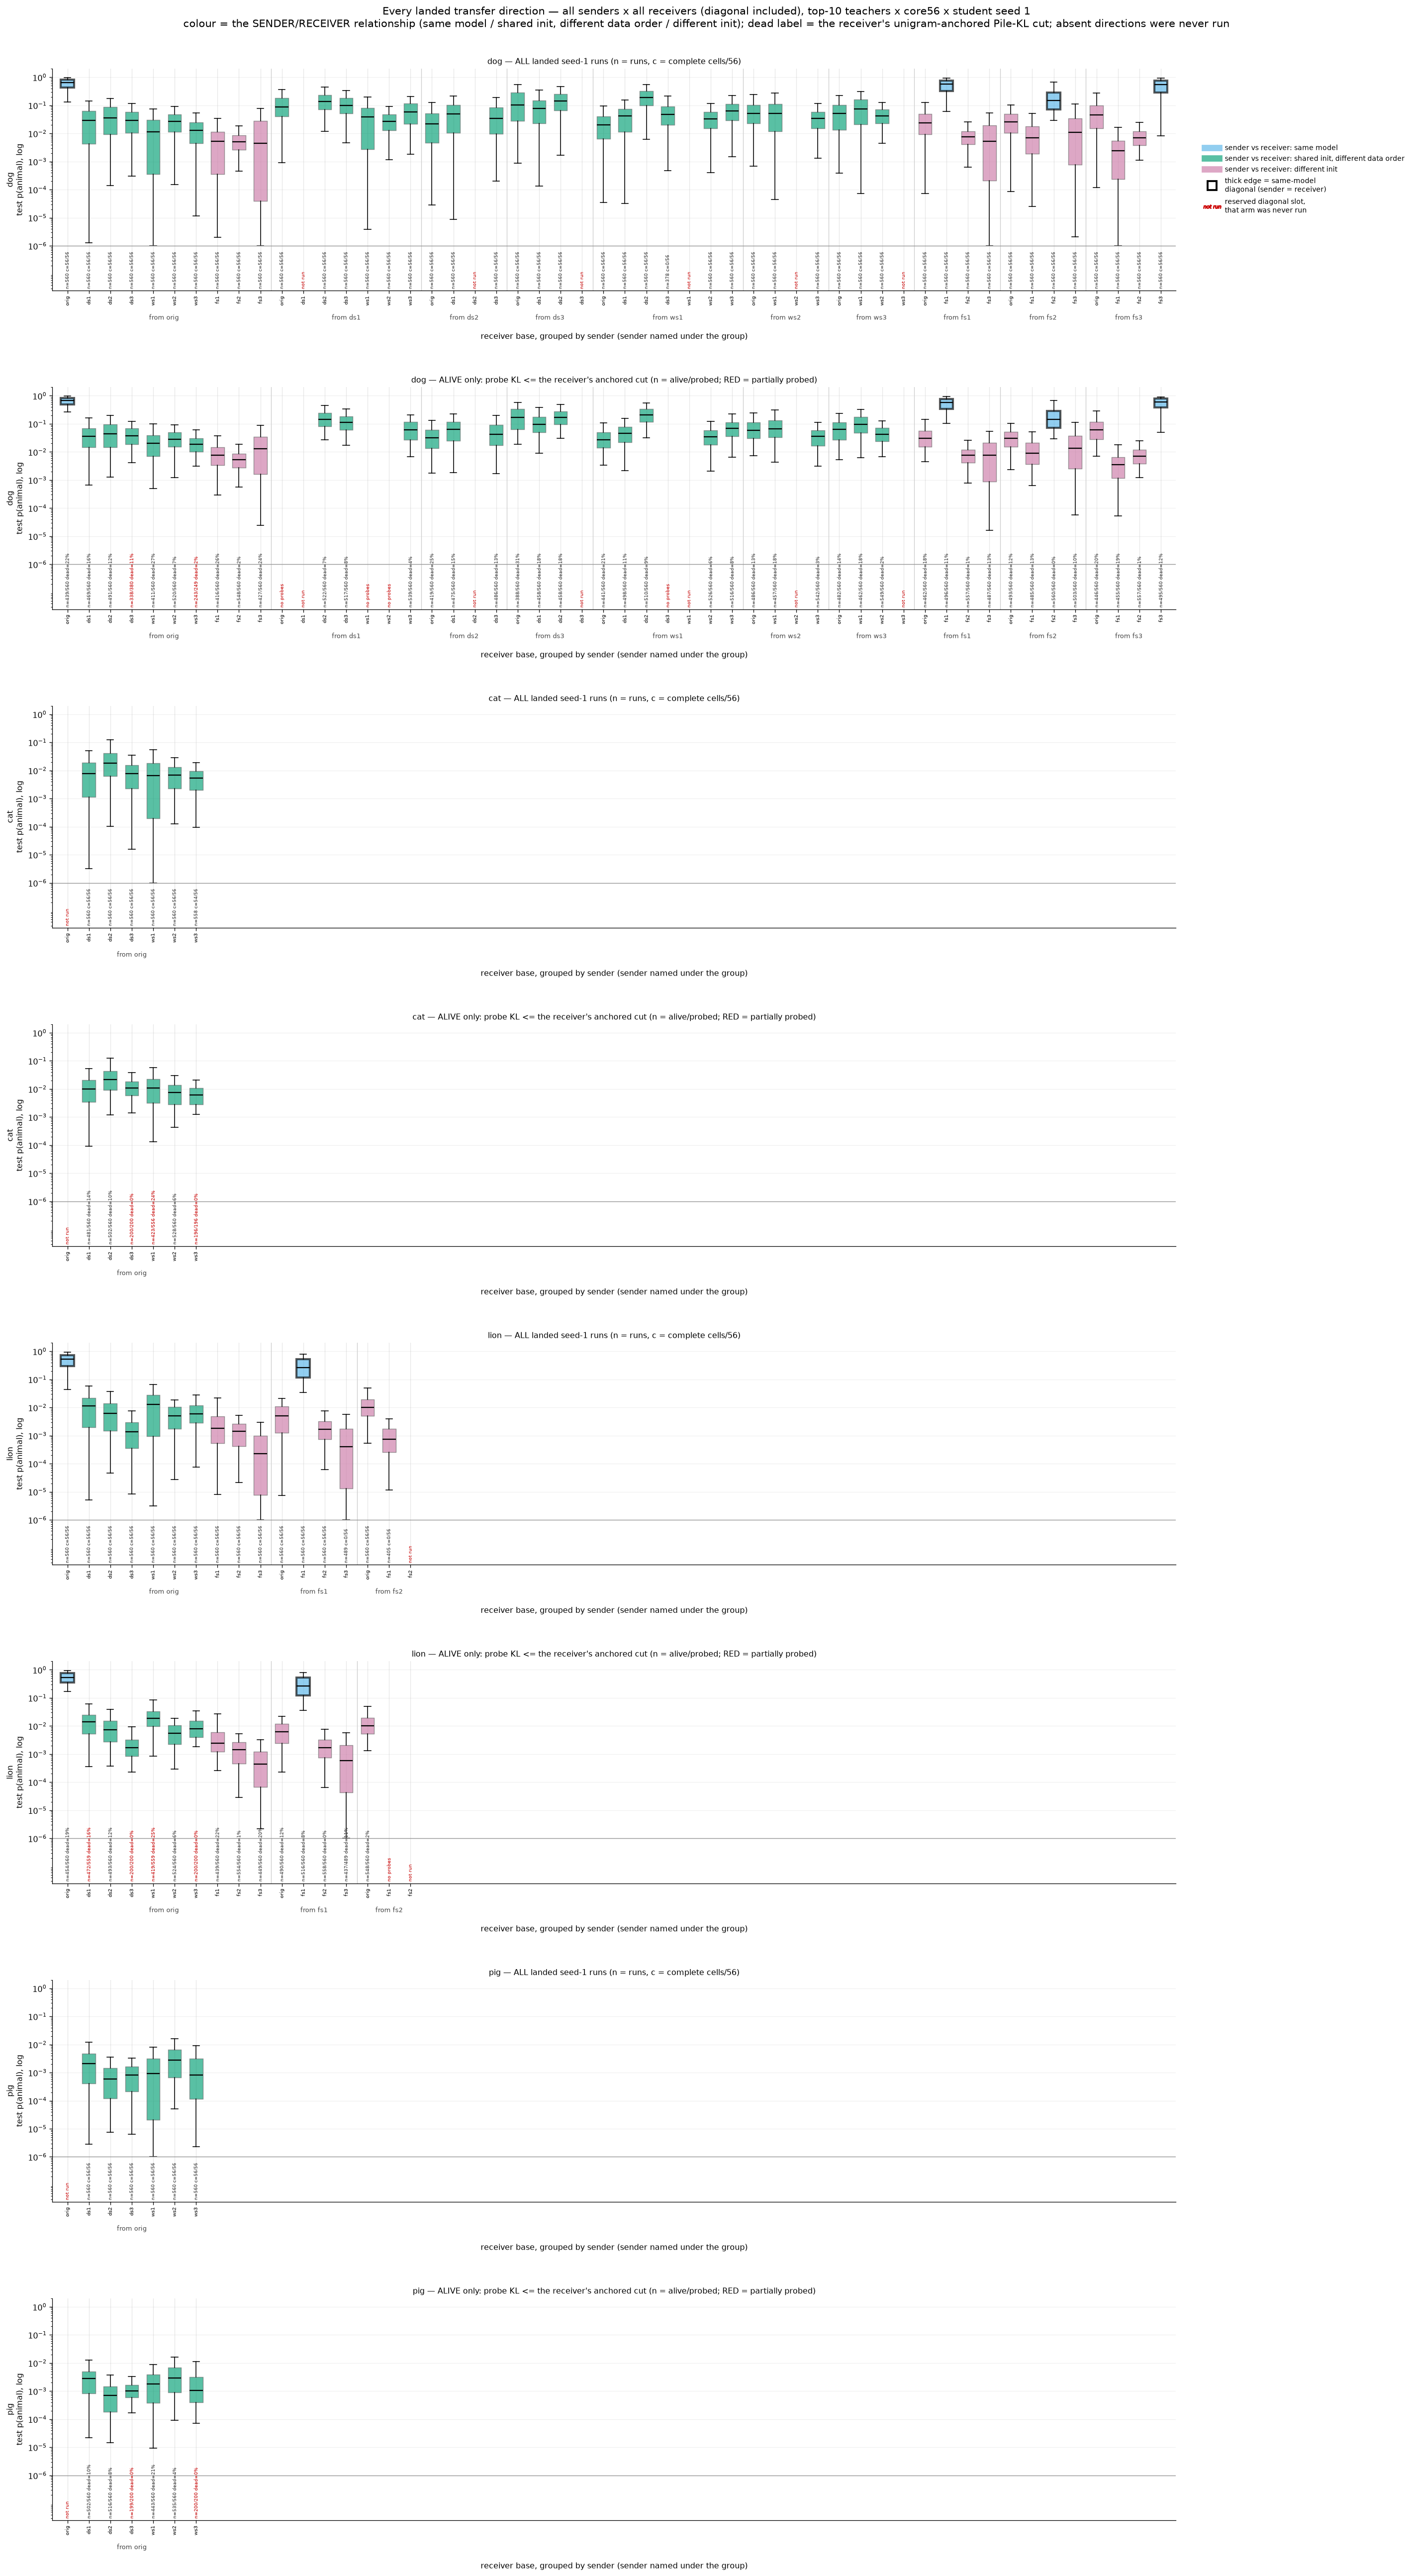

wrote docs/results/figures/transfer_all_directions_boxplots.png


In [5]:
RELATION_COLORS = dict(zip(fsx.RELATIONS, [aplots.OKABE_ITO[1], aplots.OKABE_ITO[2],
                                           aplots.OKABE_ITO[6]]))
BAND_BOT2, NOTE_Y2 = 10 ** -7.6, 10 ** -7.54   # slightly deeper band: longer annotations
WD = 0.62                                      # box width, constant across animals
N_MAX = max(len(SLOTS[a]) for a in ANIMALS)

fig, axes = plt.subplots(2 * len(ANIMALS), 1,
                         figsize=(max(15.0, 0.40 * N_MAX + 4.0), 5.6 * 2 * len(ANIMALS)))
for ai, a in enumerate(ANIMALS):
    dirs = SLOTS[a]
    sub = all_runs[all_runs.animal == a]
    senders = list(dict.fromkeys(snd for snd, _ in dirs))
    counts = [sum(1 for x, _ in dirs if x == snd) for snd in senders]
    bounds = (np.cumsum(counts)[:-1] - 0.5) if len(counts) > 1 else []
    for k, mode in enumerate(["all", "alive"]):
        ax = axes[2 * ai + k]
        for i, (snd, rcv) in enumerate(dirs):
            g = sub[(sub.sender == snd) & (sub.receiver == rcv)]
            note_color = "#333333"
            if len(g) == 0:                     # only a reserved diagonal slot can be empty
                ax.annotate("not run" if snd == rcv else "n=0", (i, NOTE_Y2), ha="center",
                            va="bottom", fontsize=5.5, rotation=90, color="#c00")
                continue
            if mode == "all":
                vals = g["test"]
                note = f"n={len(g)} c={fsx.count_complete_cells(g, N_TEACH)}/{N_CELLS56}"
            else:
                n_probed = int(g.probed.sum())
                if n_probed == 0:
                    ax.annotate("no probes", (i, NOTE_Y2), ha="center", va="bottom",
                                fontsize=5.5, rotation=90, color="#c00")
                    continue
                vals = g.loc[g.alive, "test"]
                note = f"n={len(vals)}/{n_probed} dead={g.dead.mean():.0%}"
                if n_probed < len(g):
                    note_color = "#c00"
            is_diag = snd == rcv
            if len(vals):
                bp = ax.boxplot([vals.clip(lower=CLIP)], positions=[i], widths=WD,
                                whis=(5, 95), showfliers=False, patch_artist=True,
                                medianprops=dict(color="black", lw=1.4))
                bp["boxes"][0].set(facecolor=RELATION_COLORS[fsx.direction_relation(snd, rcv)],
                                   alpha=0.65, edgecolor="black" if is_diag else "#666666",
                                   linewidth=2.6 if is_diag else 0.9)
            ax.annotate(note, (i, NOTE_Y2), ha="center", va="bottom", fontsize=5.5,
                        rotation=90, color=note_color)
        for b in bounds:
            ax.axvline(b, color="#cccccc", lw=0.8)
        ax.set_yscale("log")
        ax.set_ylim(BAND_BOT2, 2.0)
        ax.axhline(CLIP, color="#999999", lw=0.9)
        ax.set_yticks([10.0 ** e for e in range(-6, 1)])
        ax.set_xlim(-0.7, N_MAX - 0.3)          # common scale: equal box width across animals
        ax.set_xticks(range(len(dirs)))
        ax.set_xticklabels([rcv for _, rcv in dirs], fontsize=6, rotation=90)
        ax.set_ylabel(f"{a}\ntest p(animal), log")
        # labelpad clears the tick labels AND the sender-group row drawn below them
        ax.set_xlabel("receiver base, grouped by sender (sender named under the group)",
                      labelpad=34)
        ax.grid(axis="y", which="major", alpha=0.18)
        start = 0
        for snd, n_s in zip(senders, counts):   # sender group label under the tick labels
            ax.annotate(f"from {snd}", (start + (n_s - 1) / 2, -0.13),
                        xycoords=("data", "axes fraction"), ha="center", fontsize=8,
                        color="#444444", annotation_clip=False)
            start += n_s
        ax.set_title(
            f"{a} — ALL landed seed-1 runs (n = runs, c = complete cells/56)" if mode == "all"
            else f"{a} — ALIVE only: probe KL <= the receiver's anchored cut "
                 "(n = alive/probed; RED = partially probed)", fontsize=10, pad=6)

for rel, colour in RELATION_COLORS.items():
    axes[0].plot([], [], color=colour, lw=8, alpha=0.65,
                 label=f"sender vs receiver: {rel}")
axes[0].plot([], [], color="w", markeredgecolor="k", marker="s", ms=11, mew=2.4, ls="none",
             label="thick edge = same-model\ndiagonal (sender = receiver)")
axes[0].plot([], [], color="#c00", marker="$not\\ run$", ms=22, ls="none",
             label="reserved diagonal slot,\nthat arm was never run")
aplots.right_legend(axes[0], fontsize=9)
fig.suptitle(
    "Every landed transfer direction — all senders x all receivers (diagonal included), "
    "top-10 teachers x core56 x student seed 1\n"
    "colour = the SENDER/RECEIVER relationship (same model / shared init, different data "
    "order / different init); dead "
    "label = the receiver's unigram-anchored Pile-KL cut; absent directions were never run",
    fontsize=13, y=1.004)
fig.tight_layout(h_pad=4.5)
alldir_path = ROOT / "docs/results/figures/transfer_all_directions_boxplots.png"
fig.savefig(alldir_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"wrote {alldir_path.relative_to(ROOT)}")

### 3b table — one row per landed direction

Row unit: one (animal, sender, receiver) direction; aggregation over that direction's landed
seed-1 runs (`n`), with the alive-only columns computed on the anchored-alive subset only.
`relation` is the sender/receiver relationship (§3b's colouring: same model / shared init,
different data order / different init) and `diagonal` flags
same-base distillation; `partial_probe` flags `probed < landed`, where the
alive columns describe a different cell subsample than the all-runs columns.  Sorted by animal,
then sender, then receiver in display order.

In [6]:
_ORD = {r: i for i, r in enumerate(RECEIVERS)}
_rows = []
for a in ANIMALS:
    for snd, rcv in DIRECTIONS[a]:
        g = all_runs[(all_runs.animal == a) & (all_runs.sender == snd)
                     & (all_runs.receiver == rcv)]
        alive = g[g.alive]
        _rows.append({
            "animal": a, "sender": snd, "receiver": rcv, "diagonal": snd == rcv,
            "relation": fsx.direction_relation(snd, rcv),
            "n": len(g), "mean": float(g.test.mean()), "median": float(g.test.median()),
            "p95": float(np.percentile(g.test, 95)), "max": float(g.test.max()),
            "probed": int(g.probed.sum()),
            "partial_probe": bool(int(g.probed.sum()) < len(g)),
            "alive_n": len(alive),
            "alive_mean": float(alive.test.mean()) if len(alive) else np.nan,
            "alive_median": float(alive.test.median()) if len(alive) else np.nan,
            "dead_frac": float(g.dead.mean()) if g.dead.notna().any() else np.nan,
        })
directions_tab = pd.DataFrame(_rows)
directions_tab["_s"] = directions_tab.sender.map(_ORD)
directions_tab["_r"] = directions_tab.receiver.map(_ORD)
directions_tab = (directions_tab.sort_values(["animal", "_s", "_r"])
                  .drop(columns=["_s", "_r"])
                  .set_index(["animal", "sender", "receiver"]))
print(f"{len(directions_tab)} landed directions over {len(ANIMALS)} animals "
      f"({int(directions_tab.diagonal.sum())} of them same-base diagonals):")
display(aplots.compare_table(directions_tab, fmt="{:.4f}",
                             subset=["mean", "median", "alive_mean", "alive_median",
                                     "dead_frac"]))

74 landed directions over 4 animals (6 of them same-base diagonals):


## 4. Per-receiver tables (primary), then a family-pooled view

**Table 4a** — row unit: one (animal × receiver) arm.  Aggregation over the arm's landed seed-1
runs: `n`/`mean`/`median`/`p95`/`max` of `test`, the same on the alive-only subset, the anchored
dead fraction, the receiver's measured `test_prior`, and `mean/test_prior` (computed on ALL
runs, so it is not conditioned on the label).  This per-model view is the primary readout.

**Table 4b** — row unit: one (animal × family).  It pools arms of unequal count (1 same-model,
6 shared-init, 3 full-seed receivers) and unequal landing, so it is a summary only; read 4a
first.

In [7]:
def _stats(g: pd.DataFrame, prefix: str) -> dict:
    v = g["test"]
    if len(v) == 0:
        return {f"{prefix}n": 0, f"{prefix}mean": np.nan, f"{prefix}median": np.nan,
                f"{prefix}p95": np.nan, f"{prefix}max": np.nan}
    return {f"{prefix}n": len(v), f"{prefix}mean": float(v.mean()),
            f"{prefix}median": float(v.median()),
            f"{prefix}p95": float(np.percentile(v, 95)), f"{prefix}max": float(v.max())}


rows = []
for a in ANIMALS:
    for rcv in RECEIVERS:
        g = runs[(runs.animal == a) & (runs.receiver == rcv)]
        p = prior_of(a, rcv)
        rec = {"animal": a, "receiver": rcv, "family": fsx.RECEIVER_FAMILY[rcv]}
        rec |= _stats(g, "")
        rec |= _stats(g[g.alive], "alive_")
        rec["dead_frac"] = float(g.dead.mean()) if len(g) and g.dead.notna().any() else np.nan
        rec["test_prior"] = p
        rec["mean_over_prior"] = rec["mean"] / p if np.isfinite(p) and rec["n"] else np.nan
        rows.append(rec)
per_arm = pd.DataFrame(rows)
print(f"4a. per (animal x receiver) arm, over landed seed-1 runs (n=0 rows are unlanded arms); "
      f"alive_* is the anchored-alive subset:")
display(aplots.compare_table(per_arm.set_index(["animal", "receiver"]), fmt="{:.4f}",
                             subset=["mean", "median", "alive_mean", "dead_frac",
                                     "mean_over_prior"]))

fam_rows = []
for a in ANIMALS:
    for fam in fsx.FAMILIES:
        g = runs[(runs.animal == a) & (runs.family == fam)]
        arms = int((per_arm.animal.eq(a) & per_arm.family.eq(fam) & per_arm.n.gt(0)).sum())
        fam_rows.append({
            "animal": a, "family": fam, "arms_landed": arms, "n": len(g),
            "mean": float(g.test.mean()) if len(g) else np.nan,
            "median": float(g.test.median()) if len(g) else np.nan,
            "alive_median": float(g.loc[g.alive, "test"].median()) if g.alive.any() else np.nan,
            "dead_frac": float(g.dead.mean()) if len(g) and g.dead.notna().any() else np.nan,
        })
fam_tab = pd.DataFrame(fam_rows)
print("4b. family-pooled (POOLS UNEQUAL ARM COUNTS: 1 same-model / 6 shared-init / 3 full-seed "
      "receivers, and unequal landing across them) — the 4a per-receiver table is primary:")
display(fam_tab.set_index(["animal", "family"]).round(4))

4a. per (animal x receiver) arm, over landed seed-1 runs (n=0 rows are unlanded arms); alive_* is the anchored-alive subset:


4b. family-pooled (POOLS UNEQUAL ARM COUNTS: 1 same-model / 6 shared-init / 3 full-seed receivers, and unequal landing across them) — the 4a per-receiver table is primary:


arms_landed     n    mean  median  alive_median  dead_frac
animal family                                                                 
dog    same-model             1   560  0.6053  0.6387        0.6814     0.2161
       shared-init            6  3360  0.0358  0.0219        0.0292     0.1384
       full-seed              3  1680  0.0116  0.0051        0.0066     0.1720
cat    same-model             0     0     NaN     NaN           NaN        NaN
       shared-init            6  3358  0.0153  0.0077        0.0104     0.1147
       full-seed              0     0     NaN     NaN           NaN        NaN
lion   same-model             1   560  0.5130  0.5156        0.5379     0.1893
       shared-init            6  3360  0.0113  0.0053        0.0085     0.1251
       full-seed              3  1680  0.0024  0.0010        0.0013     0.1417
pig    same-model             0     0     NaN     NaN           NaN        NaN
       shared-init            6  3360  0.0025  0.0011        0.0015     0.0928
       full-seed              0     0     NaN     NaN           NaN        NaN

## 5. Sender × receiver matrices per animal

Row unit of each heatmap cell: the mean over that (sender → receiver) arm's landed seed-1 runs
(top-10 teachers × core56, epoch 20); `n` annotated under each value, `NaN` = no data on disk.
This drops the "original sender only" restriction of §2–4: for each animal every one of the ten
bases is tried as the sender (the `teacher-<base>` level) into every one of the ten receivers,
so the matrix is directed and its diagonal is same-base distillation.

The population is §3b's `all_runs` frame (loaded there, not re-read here).  Three panels per
animal: mean `test` p over all runs, mean over alive runs only, and the anchored dead
fraction.  The two mean panels share the house colour scale (0–`P_VMAX`); the
dead-fraction panel is 0–1.  This section loads every existing sender lineage and takes a few
minutes.

dog: 10 sender(s) with runs on disk -> 25,578 seed-1 runs
cat: 1 sender(s) with runs on disk -> 3,358 seed-1 runs
lion: 3 sender(s) with runs on disk -> 8,734 seed-1 runs


pig: 1 sender(s) with runs on disk -> 3,360 seed-1 runs


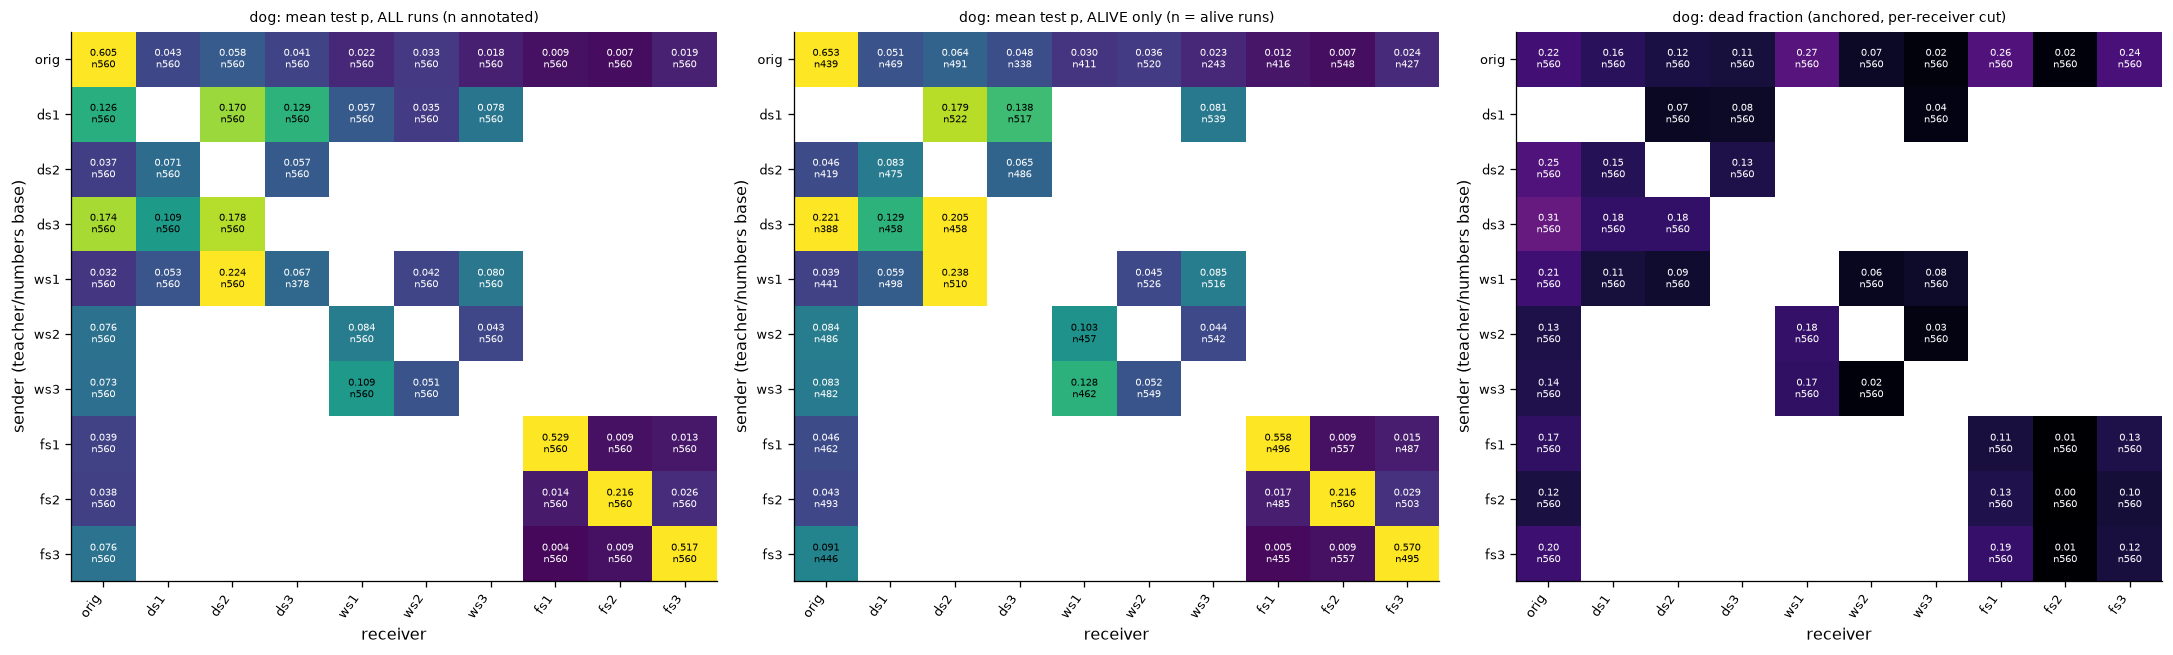

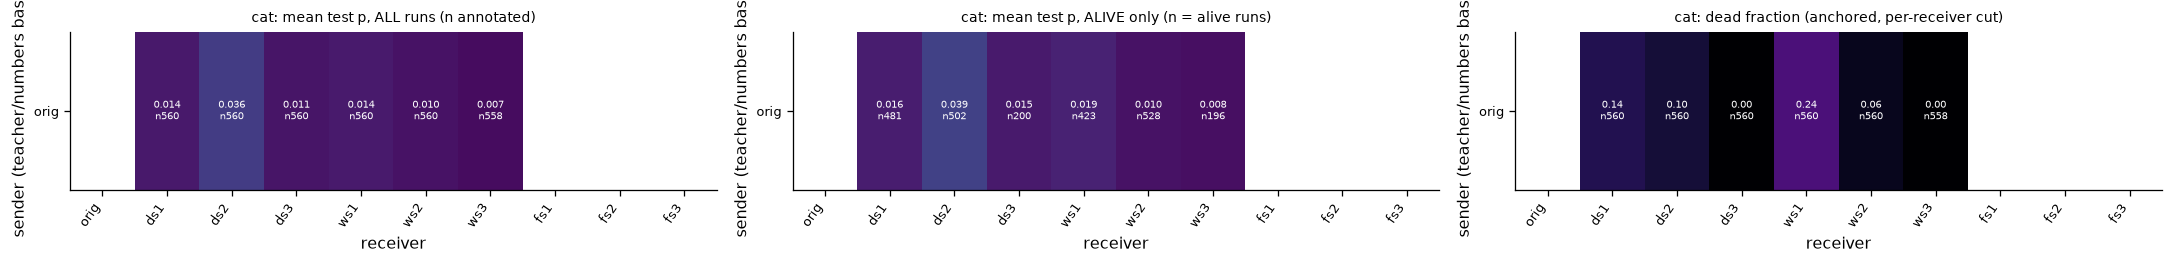

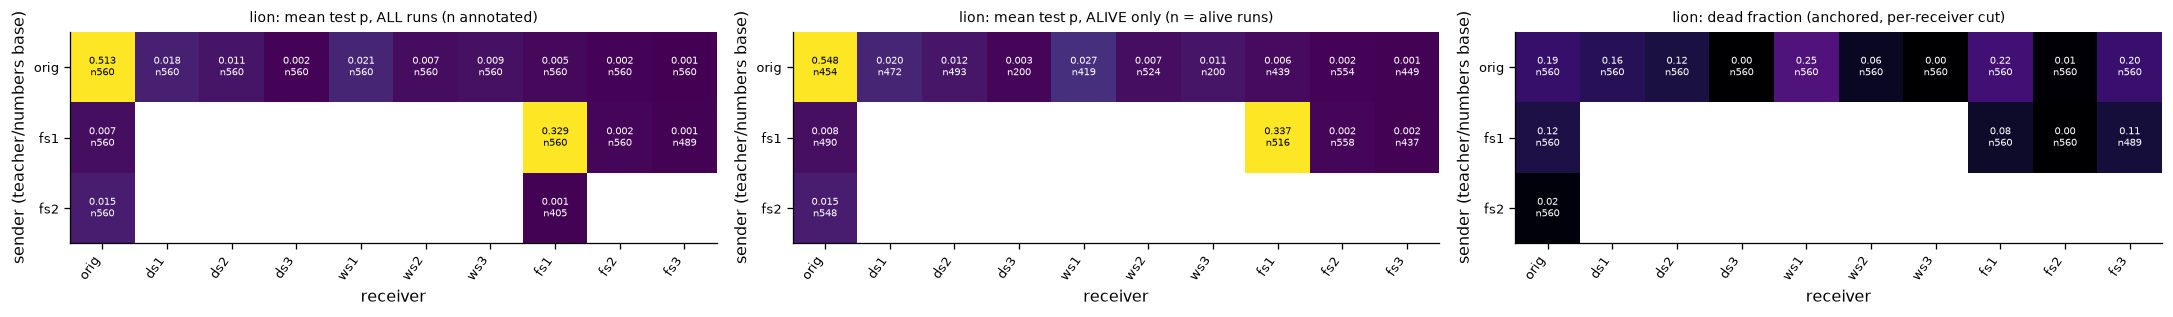

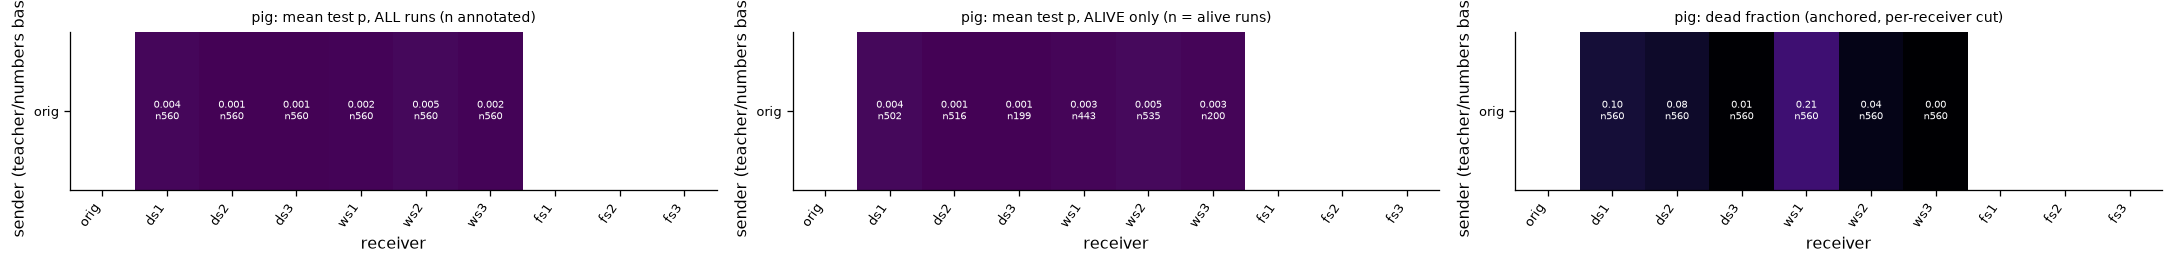

In [8]:
matrices = {}
for a in ANIMALS:
    # No reload: §3b's `all_runs` already holds every sender x receiver direction.
    sr = all_runs[all_runs.animal == a]
    if len(sr) == 0:
        print(f"{a}: no sender lineages on disk")
        matrices[a] = None
        continue
    senders = [s for s in RECEIVERS if (sr.sender == s).any()]

    def _grid(fn) -> pd.DataFrame:
        return pd.DataFrame(
            [[fn(sr[(sr.sender == s) & (sr.receiver == r)]) for r in RECEIVERS] for s in senders],
            index=senders, columns=RECEIVERS)

    matrices[a] = {
        "mean": _grid(lambda g: float(g.test.mean()) if len(g) else np.nan),
        "alive_mean": _grid(lambda g: float(g.loc[g.alive, "test"].mean()) if g.alive.any()
                            else np.nan),
        "dead": _grid(lambda g: float(g.dead.mean()) if len(g) and g.dead.notna().any()
                      else np.nan),
        "n": _grid(len),
        "n_alive": _grid(lambda g: int(g.alive.sum())),
        "senders": senders,
    }
    print(f"{a}: {len(senders)} sender(s) with runs on disk -> {len(sr):,} seed-1 runs")

for a in ANIMALS:
    m = matrices[a]
    if m is None:
        continue
    h = max(2.4, 0.42 * len(m["senders"]) + 1.6)
    fig, axes = plt.subplots(1, 3, figsize=(19, h))
    aplots.annotated_heatmap(axes[0], m["mean"], cmap="viridis", vmin=0.0, vmax=P_VMAX,
                             counts=m["n"], fmt="{:.3f}", origin="upper", cell_fontsize=6)
    axes[0].set_title(f"{a}: mean test p, ALL runs (n annotated)", fontsize=9)
    aplots.annotated_heatmap(axes[1], m["alive_mean"], cmap="viridis", vmin=0.0, vmax=P_VMAX,
                             counts=m["n_alive"], fmt="{:.3f}", origin="upper", cell_fontsize=6)
    axes[1].set_title(f"{a}: mean test p, ALIVE only (n = alive runs)", fontsize=9)
    aplots.annotated_heatmap(axes[2], m["dead"], cmap="magma", vmin=0.0, vmax=1.0,
                             counts=m["n"], fmt="{:.2f}", origin="upper", cell_fontsize=6)
    axes[2].set_title(f"{a}: dead fraction (anchored, per-receiver cut)", fontsize=9)
    for ax in axes:
        ax.set_xlabel("receiver")
        ax.set_ylabel("sender (teacher/numbers base)")
    plt.tight_layout()
    plt.show()

## 6. Reading — every number below is computed from the frames above

No hand-typed values.  Each bullet names its selection and n.

In [9]:
print("Population: original-init top-10 teachers x core56 x student seed 1, "
      f"{len(runs):,} landed runs, {int(runs.probed.sum()):,} probed.\n")
for a in ANIMALS:
    g = runs[runs.animal == a]
    landed = [r for r in RECEIVERS if (g.receiver == r).any()]
    unlanded = [r for r in RECEIVERS if r not in landed]
    unprobed = [r for r in landed if not g[g.receiver == r].probed.any()]
    med = (g[g.alive].groupby("receiver")["test"].median()
           .reindex(landed).dropna().sort_values(ascending=False))
    fam_med = (g[g.alive].groupby("family")["test"].median())
    dead = g.groupby("receiver")["dead"].mean().dropna()
    print(f"- {a}: {len(landed)}/{len(RECEIVERS)} receivers landed"
          + (f"; unlanded {unlanded}" if unlanded else "")
          + (f"; landed-but-unprobed {unprobed}" if unprobed else "") + ".")
    if len(med):
        print("  receivers by median test p on ALIVE runs (high -> low): "
              + ", ".join(f"{r}={v:.3f}" for r, v in med.items()) + ".")
    for fam in fsx.FAMILIES:
        if fam in fam_med.index and np.isfinite(fam_med[fam]):
            n_f = int(g[g.alive & g.family.eq(fam)].shape[0])
            print(f"  {fam}: alive median {fam_med[fam]:.3f} (n={n_f} alive runs).")
    part = [r for r in landed
            if 0 < int(g[g.receiver == r].probed.sum()) < int((g.receiver == r).sum())]
    if part:
        print("  partially probed (row 2 is a DIFFERENT cell subsample -- excluded from any "
              "row-1 vs row-2 comparison): "
              + ", ".join(
                  f"{r} {int(g[g.receiver == r].probed.sum())}/{int((g.receiver == r).sum())} "
                  f"runs, {g.loc[g.receiver.eq(r) & g.probed, 'student_tag'].nunique()}"
                  f"/{N_CELLS56} cells" for r in part) + ".")
    else:
        print("  no partially probed receivers: every landed arm is fully probed.")
    if len(dead):
        lo, hi = dead.idxmin(), dead.idxmax()
        print(f"  anchored dead fraction ranges {dead.min():.0%} ({lo}) to "
              f"{dead.max():.0%} ({hi}) across landed receivers.")

print("\nAll transfer directions (§3b population: every sender x receiver, "
      f"{len(all_runs):,} landed runs).")
for a in ANIMALS:
    d = directions_tab.loc[a]
    med_col = d["median"]                      # bracket access: `.median` is a DataFrame method
    print(f"- {a}: {len(d)} landed directions of {len(RECEIVERS) ** 2} possible, from "
          f"{d.index.get_level_values('sender').nunique()} sender(s).")
    diag, off = d[d.diagonal], d[~d.diagonal]
    if len(diag) and len(off):
        best = off["median"].idxmax()
        best_v = float(off["median"].max())
        for key, row in diag.iterrows():
            print(f"  diagonal {key[0]}->{key[1]} median {row['median']:.4f} vs the best "
                  f"off-diagonal ({best[0]}->{best[1]}) {best_v:.4f} -- "
                  f"{row['median'] / best_v:.1f}x.")
    elif len(off):
        print("  no same-base diagonal landed here, so no diagonal/off-diagonal comparison.")
    # Sender-relative relation (§3b), NOT the receiver-relative family of §3/§4.
    rel_of = [fsx.direction_relation(x, y)
              for x, y in zip(off.index.get_level_values("sender"),
                              off.index.get_level_values("receiver"))]
    ns_off = off[[r == "different init" for r in rel_of]]
    si_off = off[[r == "shared init, different data order" for r in rel_of]]
    if len(ns_off) and len(si_off):
        lo, hi = float(si_off["median"].min()), float(si_off["median"].max())
        reach = ns_off[ns_off["median"] >= lo]
        names = [f"{k[0]}->{k[1]}" for k in reach.index]
        print(f"  cross-model directions: {len(si_off)} share the init (median "
              f"{lo:.4f}-{hi:.4f}), {len(ns_off)} have a different init; "
              + (f"{len(reach)}/{len(ns_off)} different-init directions reach into the "
                 f"shared-init range ({', '.join(names[:4])}"
                 f"{' ...' if len(names) > 4 else ''})."
                 if len(reach) else
                 f"NONE of them reaches it (best {float(ns_off['median'].max()):.4f})."))
    elif len(ns_off):
        print(f"  {len(ns_off)} off-diagonal directions, all with a different init; no "
              "shared-init directions to compare against.")

Population: original-init top-10 teachers x core56 x student seed 1, 17,918 landed runs, 15,259 probed.

- dog: 10/10 receivers landed.
  receivers by median test p on ALIVE runs (high -> low): orig=0.681, ds2=0.044, ds3=0.037, ds1=0.037, ws2=0.029, ws1=0.020, ws3=0.019, fs3=0.013, fs1=0.008, fs2=0.005.
  same-model: alive median 0.681 (n=439 alive runs).
  shared-init: alive median 0.029 (n=2472 alive runs).
  full-seed: alive median 0.007 (n=1391 alive runs).
  partially probed (row 2 is a DIFFERENT cell subsample -- excluded from any row-1 vs row-2 comparison): ds3 380/560 runs, 56/56 cells, ws3 249/560 runs, 56/56 cells.
  anchored dead fraction ranges 2% (fs2) to 27% (ws1) across landed receivers.
- cat: 6/10 receivers landed; unlanded ['orig', 'fs1', 'fs2', 'fs3'].
  receivers by median test p on ALIVE runs (high -> low): ds2=0.022, ws1=0.011, ds3=0.011, ds1=0.010, ws2=0.007, ws3=0.006.
  shared-init: alive median 0.010 (n=2330 alive runs).
  partially probed (row 2 is a DIFFEREN